In [14]:
import os, json
from pathlib import Path

# Cherche automatiquement le fichier de métadonnées dans les inputs Kaggle
meta = list(Path("/kaggle/input").rglob("HAM10000_metadata.csv"))
assert meta, "HAM10000_metadata.csv introuvable : vérifie que le bon dataset est ajouté"
DATA_DIR = meta[0].parent
print("Données trouvées dans :", DATA_DIR)

OUT_DIR = Path("/kaggle/working")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Nombre d'images uniques (on doit en trouver 10 015)
uniques = {p.stem for p in Path("/kaggle/input").rglob("*.jpg")}
print("Images uniques :", len(uniques))

Données trouvées dans : /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
Images uniques : 10015


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

# Les 7 classes : code -> (nom en français, niveau de risque)
CLASSES = {
    "akiec": ("Kératose actinique / carcinome intra-épithélial", "précancéreux"),
    "bcc":   ("Carcinome basocellulaire", "malin"),
    "bkl":   ("Kératose bénigne", "bénin"),
    "df":    ("Dermatofibrome", "bénin"),
    "mel":   ("Mélanome", "malin"),
    "nv":    ("Naevus mélanocytaire", "bénin"),
    "vasc":  ("Lésion vasculaire", "bénin"),
}
CODES = sorted(CLASSES)                          # ordre alphabétique = numéro de classe
LABEL = {c: i for i, c in enumerate(CODES)}      # akiec=0, bcc=1, ... vasc=6
RISK_COLOR = {"bénin": "#4c9a6a", "précancéreux": "#e0a030", "malin": "#c8453c"}

In [16]:
df = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")

# Associer chaque image_id au chemin de son fichier (images réparties dans part_1 et part_2)
paths = {p.stem: str(p) for p in Path("/kaggle/input").rglob("*.jpg")}
df["path"] = df["image_id"].map(paths)

print(f"{len(df):,} lignes, {len(paths):,} images trouvées")
print("Images sans fichier :", df["path"].isna().sum())
df.head()

10,015 lignes, 10,015 images trouvées
Images sans fichier : 0


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/kaggle/input/datasets/kmader/skin-cancer-mnis...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/kaggle/input/datasets/kmader/skin-cancer-mnis...


In [17]:
print("Valeurs manquantes :")
print(df.isna().sum())
print("\nValeurs 'unknown' :")
print((df == "unknown").sum()[lambda s: s > 0])

Valeurs manquantes :
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
path             0
dtype: int64

Valeurs 'unknown' :
sex              57
localization    234
dtype: int64


,nom,risque,images,%
dx,,,,
nv,Naevus mélanocytaire,bénin,6705,66.9
mel,Mélanome,malin,1113,11.1
bkl,Kératose bénigne,bénin,1099,11.0
bcc,Carcinome basocellulaire,malin,514,5.1
akiec,Kératose actinique / carcinome intra-épithélial,précancéreux,327,3.3
vasc,Lésion vasculaire,bénin,142,1.4
df,Dermatofibrome,bénin,115,1.1


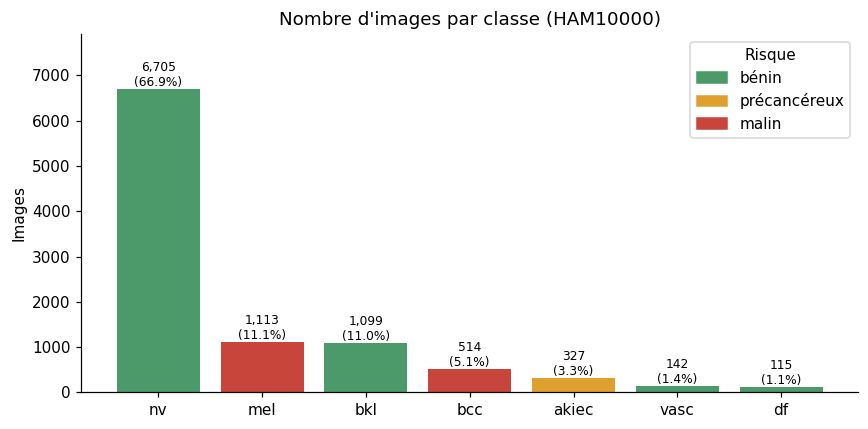

La classe nv a 58× plus d'images que df.


In [18]:
from matplotlib.patches import Patch

counts = df["dx"].value_counts()
summary = pd.DataFrame({
    "nom": [CLASSES[c][0] for c in counts.index],
    "risque": [CLASSES[c][1] for c in counts.index],
    "images": counts.values,
    "%": (100 * counts.values / counts.sum()).round(1),
}, index=counts.index)
display(summary)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color=[RISK_COLOR[CLASSES[c][1]] for c in counts.index])
ax.bar_label(bars, labels=[f"{v:,}\n({p}%)" for v, p in zip(counts.values, summary["%"])], fontsize=8)
ax.set_title("Nombre d'images par classe (HAM10000)")
ax.set_ylabel("Images")
ax.set_ylim(0, counts.max() * 1.18)
ax.legend(handles=[Patch(color=v, label=k) for k, v in RISK_COLOR.items()], title="Risque")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_repartition_classes.png"); plt.show()

print(f"La classe {counts.idxmax()} a {counts.max() / counts.min():.0f}× plus d'images que {counts.idxmin()}.")

df["risque"] = df["dx"].map(lambda c: CLASSES[c][1])
risk = df["risque"].value_counts()

10,015 images pour 7,470 lésions uniques
1,956 lésions ont plusieurs images (jusqu'à 6)
OK : chaque lésion a un seul diagnostic.


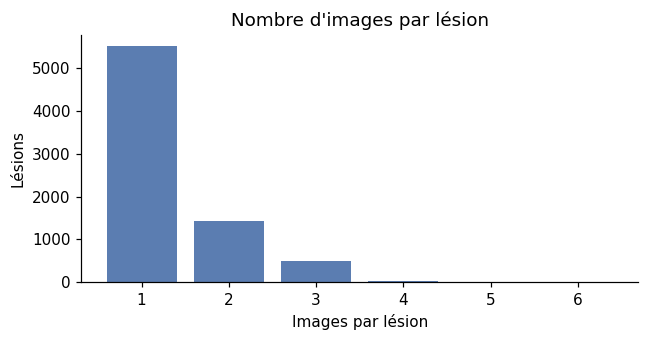

In [19]:
per_lesion = df.groupby("lesion_id").size()
print(f"{len(df):,} images pour {df['lesion_id'].nunique():,} lésions uniques")
print(f"{(per_lesion > 1).sum():,} lésions ont plusieurs images (jusqu'à {per_lesion.max()})")

# Chaque lésion doit avoir un seul diagnostic (nécessaire pour le split)
assert (df.groupby("lesion_id")["dx"].nunique() == 1).all()
print("OK : chaque lésion a un seul diagnostic.")

vc = per_lesion.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(vc.index.astype(str), vc.values, color="#5b7db1")
ax.set_xlabel("Images par lésion"); ax.set_ylabel("Lésions"); ax.set_title("Nombre d'images par lésion")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_images_par_lesion.png"); plt.show()

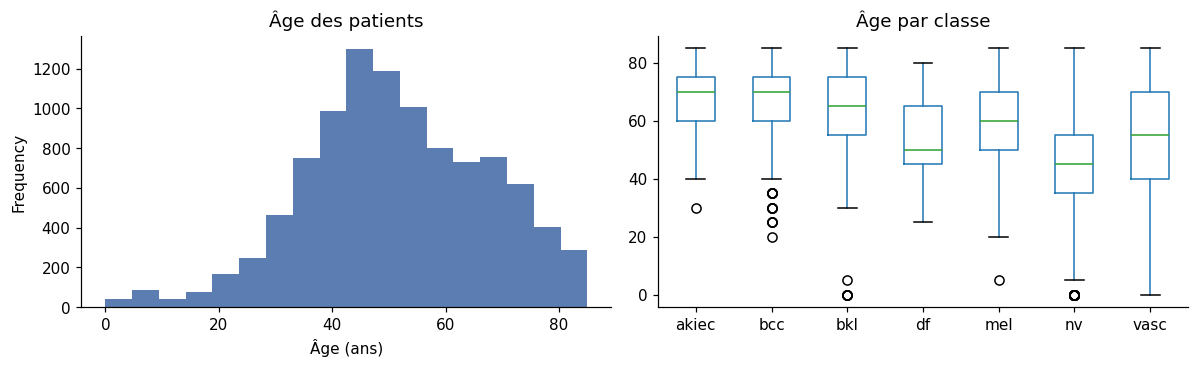

dx
akiec    70.0
bcc      70.0
bkl      65.0
df       50.0
mel      60.0
nv       45.0
vasc     55.0
Name: âge médian, dtype: float64


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
df["age"].plot.hist(bins=18, ax=axes[0], color="#5b7db1")
axes[0].set_title("Âge des patients"); axes[0].set_xlabel("Âge (ans)")
df.boxplot(column="age", by="dx", ax=axes[1], grid=False)
axes[1].set_title("Âge par classe"); axes[1].set_xlabel("")
fig.suptitle("")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_age.png"); plt.show()
print(df.groupby("dx")["age"].median().rename("âge médian"))

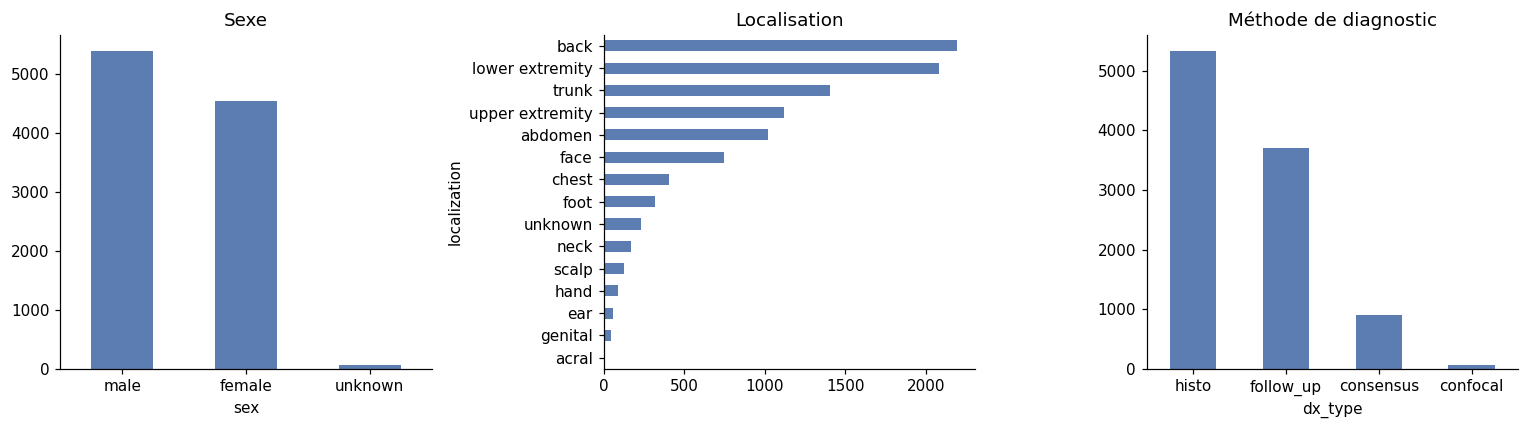

dx_type,confocal,consensus,follow_up,histo
dx,,,,
akiec,0,0,0,327
bcc,0,0,0,514
bkl,69,264,0,766
df,0,60,0,55
mel,0,0,0,1113
nv,0,503,3704,2498
vasc,0,75,0,67


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df["sex"].value_counts().plot.bar(ax=axes[0], color="#5b7db1", rot=0); axes[0].set_title("Sexe")
df["localization"].value_counts().plot.barh(ax=axes[1], color="#5b7db1")
axes[1].set_title("Localisation"); axes[1].invert_yaxis()
df["dx_type"].value_counts().plot.bar(ax=axes[2], color="#5b7db1", rot=0); axes[2].set_title("Méthode de diagnostic")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_sexe_localisation_dxtype.png"); plt.show()

pd.crosstab(df["dx"], df["dx_type"])

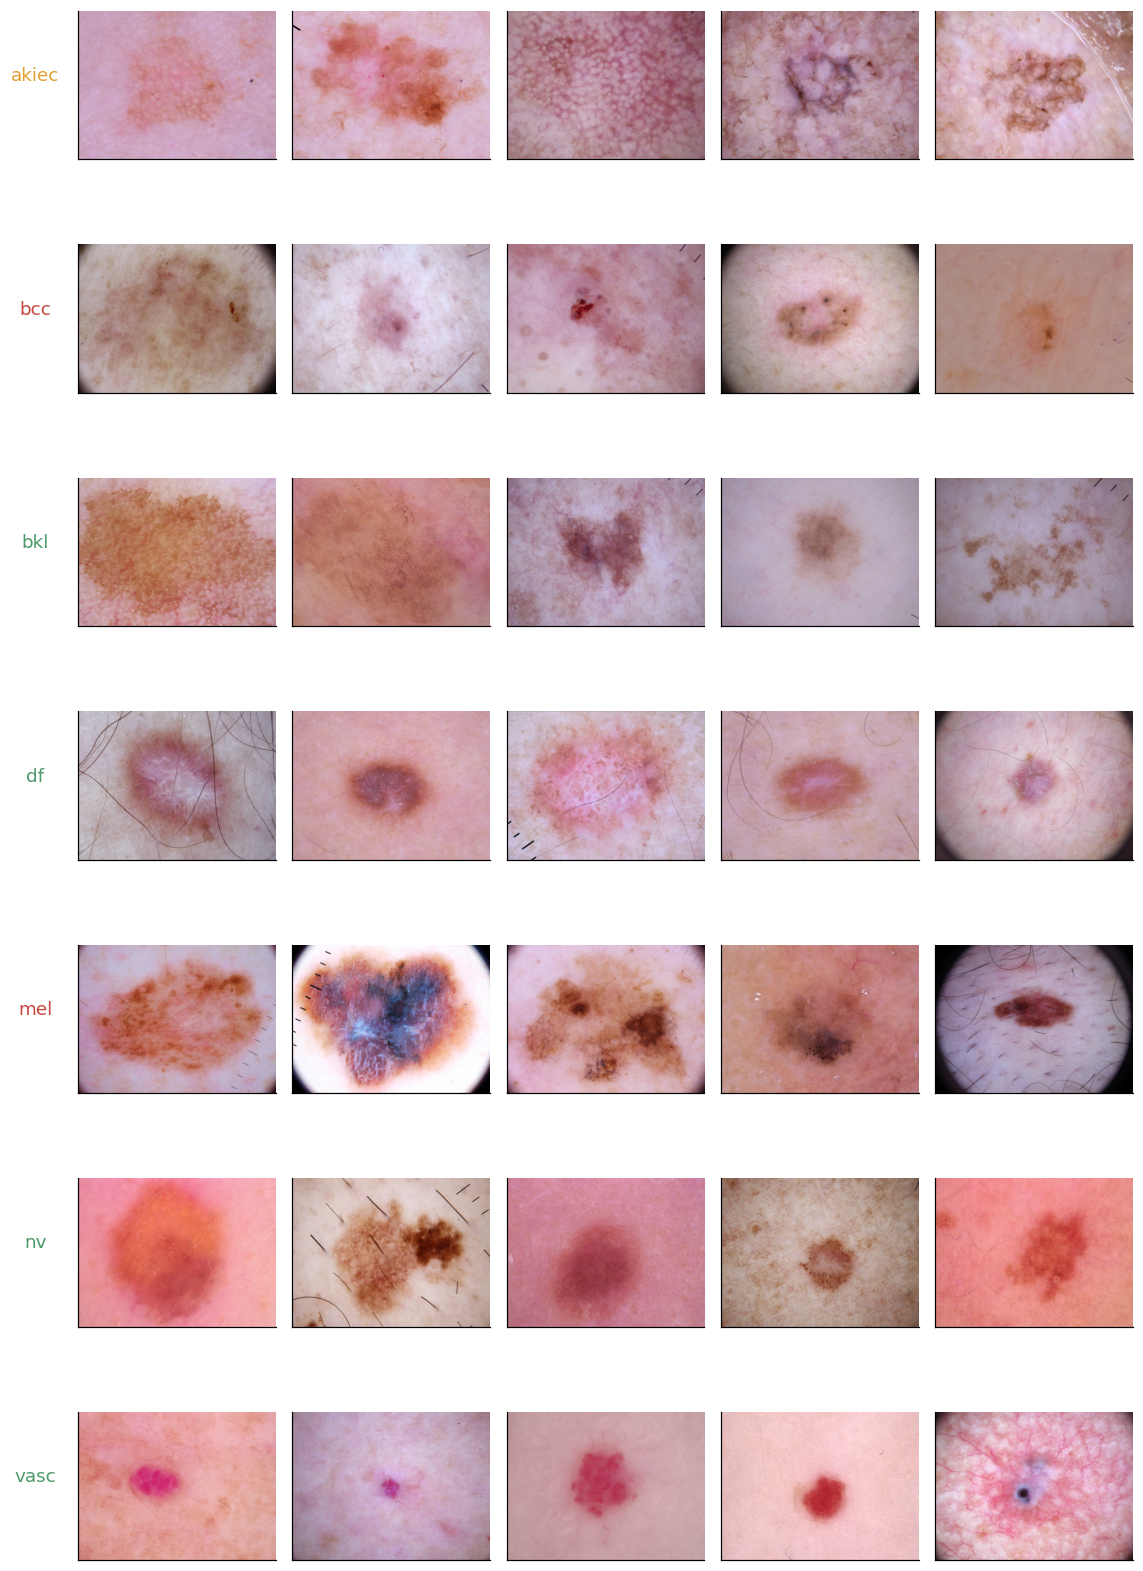

In [22]:
N = 5
fig, axes = plt.subplots(len(CODES), N, figsize=(N * 2.1, len(CODES) * 2.2))
for r, c in enumerate(CODES):
    sample = df[df["dx"] == c].sample(N, random_state=SEED)
    for k, p in enumerate(sample["path"]):
        ax = axes[r, k]
        ax.imshow(Image.open(p)); ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(c, fontsize=12, rotation=0, labelpad=28, color=RISK_COLOR[CLASSES[c][1]])
plt.tight_layout(); plt.savefig(FIG_DIR / "05_exemples_images.png"); plt.show()

In [23]:
from sklearn.model_selection import train_test_split

# On découpe la liste des LÉSIONS (une ligne par lesion_id), pas des images
lesions = df.drop_duplicates("lesion_id")[["lesion_id", "dx"]]
train_l, tmp_l = train_test_split(lesions, test_size=0.30, stratify=lesions["dx"], random_state=SEED)
val_l, test_l = train_test_split(tmp_l, test_size=0.50, stratify=tmp_l["dx"], random_state=SEED)

# Chaque image hérite de l'ensemble de sa lésion
split_of = {**dict.fromkeys(train_l["lesion_id"], "train"),
            **dict.fromkeys(val_l["lesion_id"], "val"),
            **dict.fromkeys(test_l["lesion_id"], "test")}
df["split"] = df["lesion_id"].map(split_of)
df["label"] = df["dx"].map(LABEL)

print("Images :", df["split"].value_counts().reindex(["train", "val", "test"]).to_dict())

Images : {'train': 7002, 'val': 1532, 'test': 1481}


Toutes les vérifications sont passées ✅


images                %            
split  train   val test train   val  test
dx                                       
akiec    230    51   46   3.3   3.3   3.1
bcc      366    77   71   5.2   5.0   4.8
bkl      774   157  168  11.1  10.2  11.3
df        76    19   20   1.1   1.2   1.4
mel      778   170  165  11.1  11.1  11.1
nv      4679  1034  992  66.8  67.5  67.0
vasc      99    24   19   1.4   1.6   1.3

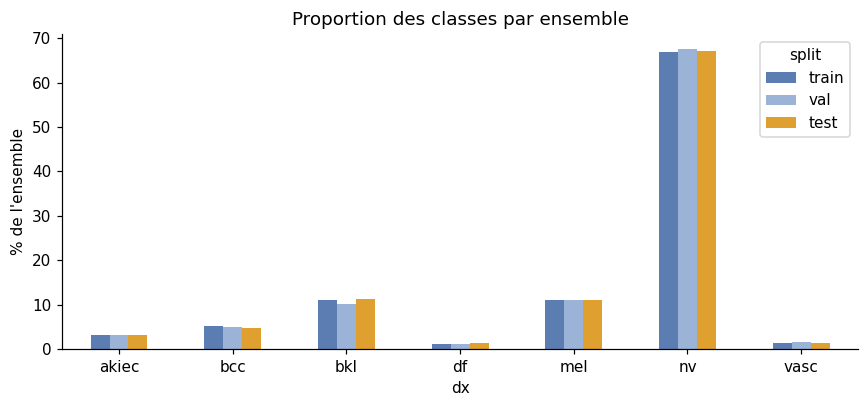

In [24]:
assert df["split"].notna().all()

sets = {s: set(df.loc[df["split"] == s, "lesion_id"]) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"]),  "Fuite train/val"
assert not (sets["train"] & sets["test"]), "Fuite train/test"
assert not (sets["val"] & sets["test"]),   "Fuite val/test"
assert (pd.crosstab(df["dx"], df["split"]) > 0).all().all(), "Une classe manque dans un ensemble"
print("Toutes les vérifications sont passées ✅")

tab = pd.crosstab(df["dx"], df["split"])[["train", "val", "test"]]
pct = (100 * tab / tab.sum()).round(1)
display(pd.concat({"images": tab, "%": pct}, axis=1))

fig, ax = plt.subplots(figsize=(8, 3.8))
pct.plot.bar(ax=ax, rot=0, color=["#5b7db1", "#9bb3d6", "#e0a030"])
ax.set_ylabel("% de l'ensemble"); ax.set_title("Proportion des classes par ensemble")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_split_proportions.png"); plt.show()

In [25]:
cols = ["image_id", "lesion_id", "dx", "label", "risque", "split", "age", "sex", "localization", "dx_type"]
df[cols].sort_values(["split", "image_id"]).to_csv(OUT_DIR / "splits.csv", index=False)

with open(OUT_DIR / "classes.json", "w", encoding="utf-8") as f:
    json.dump({"codes": CODES, "label_index": LABEL,
               "noms": {c: CLASSES[c][0] for c in CODES},
               "risque": {c: CLASSES[c][1] for c in CODES},
               "seed": SEED, "split": "70/15/15 par lesion_id, stratifié par dx"},
              f, ensure_ascii=False, indent=2)

# Poids de classe pour la Weighted Cross-Entropy de M2
train_counts = df.loc[df["split"] == "train", "dx"].value_counts().reindex(CODES)
weights = (train_counts.sum() / (len(CODES) * train_counts)).round(4)
weights.rename("poids").to_csv(OUT_DIR / "class_weights.csv")
display(weights.to_frame("poids"))
print("Fichiers créés dans", OUT_DIR)

,poids
dx,
akiec,4.3491
bcc,2.7330
bkl,1.2924
df,13.1617
mel,1.2857
nv,0.2138
vasc,10.1039


Fichiers créés dans /kaggle/working


In [26]:
n = len(df)
print(f"""RÉSUMÉ — HAM10000
- {n:,} images, {df['lesion_id'].nunique():,} lésions uniques, 7 classes
- Majoritaire : {counts.idxmax()} ({100*counts.max()/n:.1f} %) ; minoritaire : {counts.idxmin()} ({100*counts.min()/n:.1f} %)
- Risque : bénin {100*risk['bénin']/n:.1f} %, précancéreux {100*risk['précancéreux']/n:.1f} %, malin {100*risk['malin']/n:.1f} %
- Âge médian : {df['age'].median():.0f} ans ({df['age'].isna().sum()} valeurs manquantes)
- Split : train {(df.split=='train').sum():,} / val {(df.split=='val').sum():,} / test {(df.split=='test').sum():,} images
- Aucune lésion partagée entre ensembles ✅""")

RÉSUMÉ — HAM10000
- 10,015 images, 7,470 lésions uniques, 7 classes
- Majoritaire : nv (66.9 %) ; minoritaire : df (1.1 %)
- Risque : bénin 80.5 %, précancéreux 3.3 %, malin 16.2 %
- Âge médian : 50 ans (57 valeurs manquantes)
- Split : train 7,002 / val 1,532 / test 1,481 images
- Aucune lésion partagée entre ensembles ✅


In [27]:
import shutil
shutil.make_archive("/kaggle/working/resultats_M1", "zip", "/kaggle/working", )
print("Archive créée : resultats_M1.zip")

Archive créée : resultats_M1.zip


In [28]:
from IPython.display import FileLink
FileLink("resultats_M1.zip")

/kaggle/working/resultats_M1.zip